# Explore model results

Load the data using [MIKE IO](https://dhi.github.io/mikeio/) and review it. Data is stored as a dfsu file. Specific points are stored in a dfs0 file.

In [ ]:
import mikeio
import matplotlib.pyplot as plt 
plt.rcParams.update({'font.size': 10})

In [18]:
mr_fldr

'\\\\\\DKCPH1-STOR.DHI.DK\\Projects\\11561006\\WaterBench\\WaterBench-MIKE3HD-Oresund\\output\\2024'

In [23]:
# mr_fldr = "../output_sample/"
mr_fldr = '\\\\DKCPH1-STOR.DHI.DK\\Projects\\11561006\\WaterBench\\WaterBench-MIKE3HD-Oresund\\output\\2024\\'.replace("\\","/") # Change the output folder if needed  

fig_fldr = "../figures/"
save_png = False

## Open the model result file

In [25]:
dfs = mikeio.open(f"{mr_fldr}2D.dfsu")
dfs

<mikeio.Dfsu2DH>
number of elements: 3700
number of nodes: 2090
projection: UTM-33
items:
  0:  Surface elevation <Surface Elevation> (meter)
  1:  Depth averaged U velocity <u velocity component> (meter per sec)
  2:  Depth averaged V velocity <v velocity component> (meter per sec)
time: 2024-01-01 00:00:00 - 2024-12-31 23:00:00 (8784 records)

## Mesh and bathymetry

In [26]:
geom = dfs.geometry

Calculate the total area covered (in km^2)

In [27]:
geom.get_element_area().sum()/(10**6)

np.float64(2056.6954425510685)

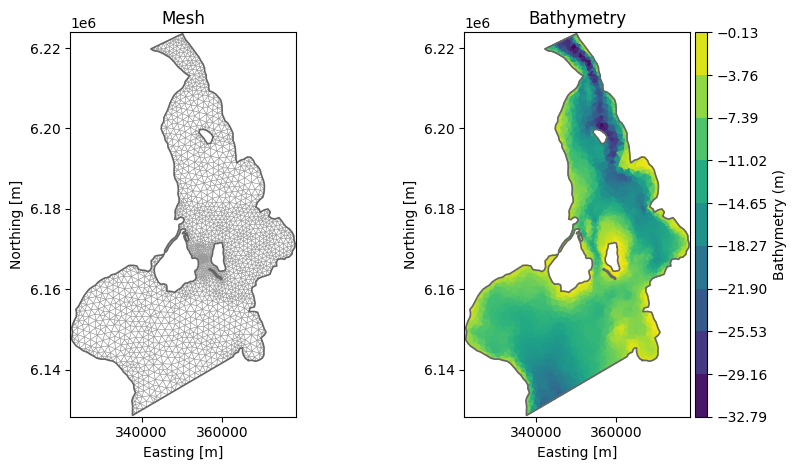

In [28]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4.8))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
if save_png:
    plt.savefig(f"{fig_fldr}geometry.png")
plt.show()

## Area plots

In [29]:
ds = dfs.read()

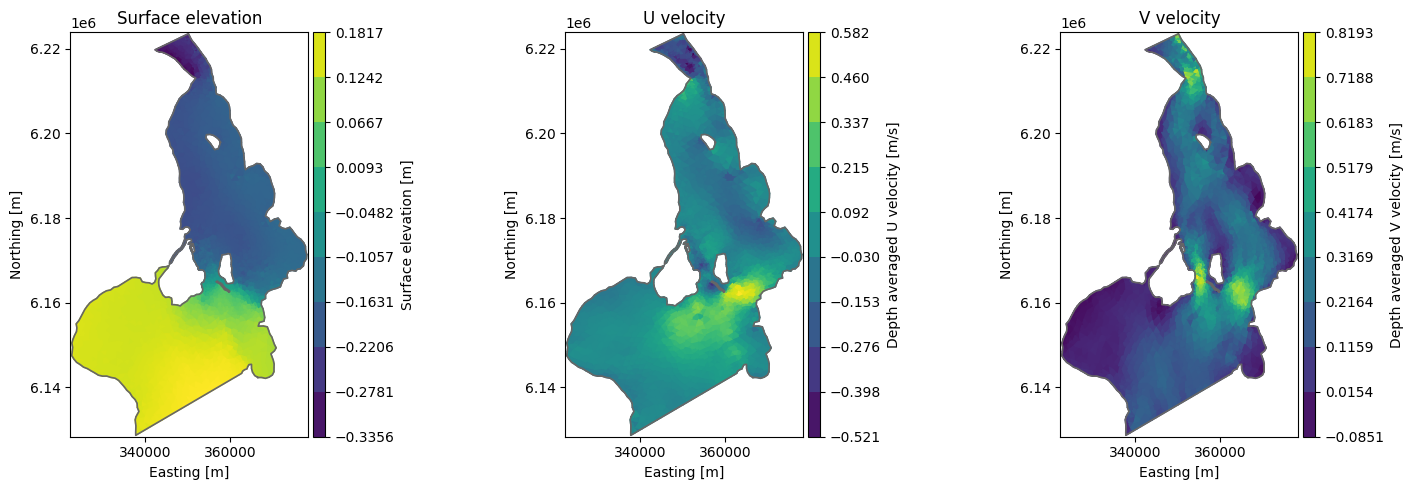

In [32]:
# Select time step and plot items
plot_time = "2024-05-01" if "2024-05-01" in ds.time else ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
ds["Surface elevation"].sel(time=plot_time).plot(ax=axs[0], title="Surface elevation")
ds["Depth averaged U velocity"].sel(time=plot_time).plot(ax=axs[1], title="U velocity")
ds["Depth averaged V velocity"].sel(time=plot_time).plot(ax=axs[2], title="V velocity")
plt.tight_layout()
plt.show()

## Timeseries

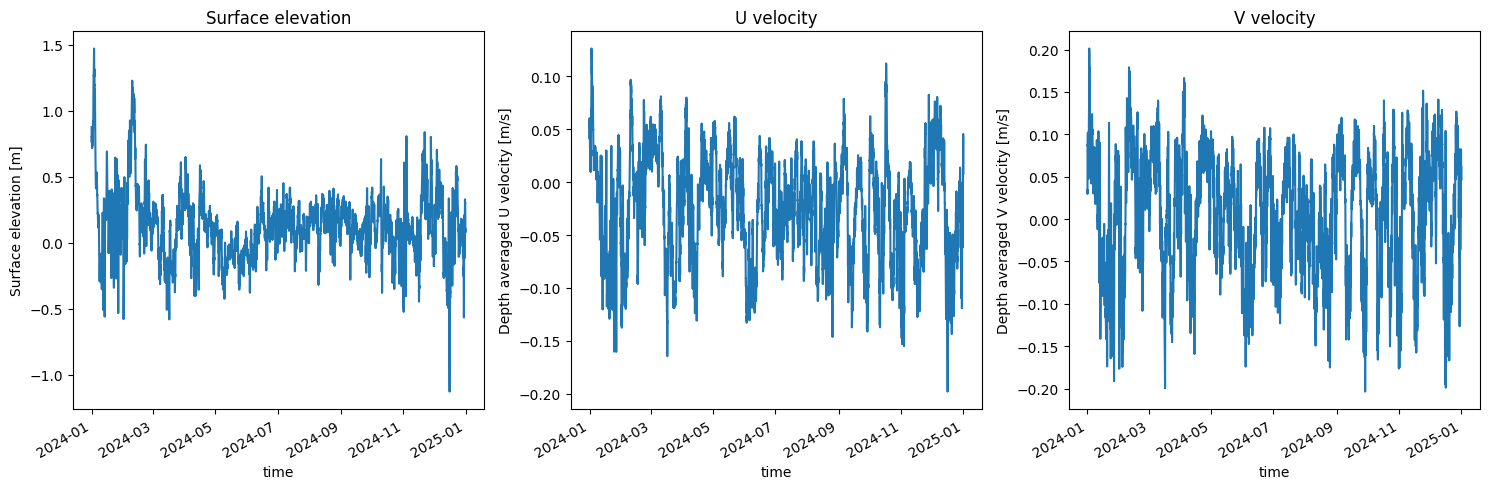

In [52]:
# Select spatial point and plot items
p = (3.4e5, 6.15e6)
fig,axs = plt.subplots(1,3, figsize=(15,5))
ds["Surface elevation"].sel(x=p[0],y=p[1]).plot(ax=axs[0],title="Surface elevation")
ds["Depth averaged U velocity"].sel(x=p[0],y=p[1]).plot(ax=axs[1],title="U velocity")
ds["Depth averaged V velocity"].sel(x=p[0],y=p[1]).plot(ax=axs[2],title="V velocity")
plt.tight_layout()
plt.show()